In [1]:
%matplotlib inline

# Notebook 3 — Radiation equilibrium and lattice comparison

Load one of the rings saved in notebooks 1 and 2. Extract the quantities needed for the comparison table in notebook 0, then repeat for the other ring.

### Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import xtrack as xt

### Load the ring

In [3]:
lattice_file = 'ring_fodo.json' # or 'ring_dba.json'
ring = xt.load(lattice_file)

Loading line from dict:   0%|          | 0/105 [00:00<?, ?it/s]

Done loading line from dict.           


### Radiation integrals

See the [radiation-integral outputs in the Xsuite reference](https://xsuite.readthedocs.io/en/latest/apireference.html).

See [Section 9.3 — "Radiation integrals" in the Xsuite physics manual](https://xsuite.github.io/xsuite/docs/physics_manual/physics_man.pdf#page=142) for the relations between radiation integrals, equilibrium emittances, energy loss, and damping rates. Damping times are the reciprocals of the amplitude damping rates.

In [4]:
# Use a sliced copy to sample the optics inside the magnets.
ring_rad = ring.copy(shallow=True)
ring_rad.slice_thick_elements(slicing_strategies=[
    xt.Strategy(slicing=None),
    xt.Strategy(slicing=xt.Uniform(100, mode='thick'), element_type=xt.Bend),
    xt.Strategy(slicing=xt.Uniform(2, mode='thick'), element_type=xt.Quadrupole),
])

Slicing line:   0%|          | 0/192 [00:00<?, ?it/s]

{'qf.0': ['qf.0_entry',
  'qf.0..entry_map',
  'qf.0..0',
  'qf.0..1',
  'qf.0..exit_map',
  'qf.0_exit'],
 '||drift_1::0': ['||drift_1'],
 'sf.0': ['sf.0'],
 '||drift_2::0': ['||drift_2'],
 'bend.0': ['bend.0_entry',
  'bend.0..entry_map',
  'bend.0..0',
  'bend.0..1',
  'bend.0..2',
  'bend.0..3',
  'bend.0..4',
  'bend.0..5',
  'bend.0..6',
  'bend.0..7',
  'bend.0..8',
  'bend.0..9',
  'bend.0..10',
  'bend.0..11',
  'bend.0..12',
  'bend.0..13',
  'bend.0..14',
  'bend.0..15',
  'bend.0..16',
  'bend.0..17',
  'bend.0..18',
  'bend.0..19',
  'bend.0..20',
  'bend.0..21',
  'bend.0..22',
  'bend.0..23',
  'bend.0..24',
  'bend.0..25',
  'bend.0..26',
  'bend.0..27',
  'bend.0..28',
  'bend.0..29',
  'bend.0..30',
  'bend.0..31',
  'bend.0..32',
  'bend.0..33',
  'bend.0..34',
  'bend.0..35',
  'bend.0..36',
  'bend.0..37',
  'bend.0..38',
  'bend.0..39',
  'bend.0..40',
  'bend.0..41',
  'bend.0..42',
  'bend.0..43',
  'bend.0..44',
  'bend.0..45',
  'bend.0..46',
  'bend.0..47',
 

In [5]:
# Compute twiss table with radiation integrals
tw_rad = ring_rad.twiss4d(radiation_integrals=True)

### Energy loss per turn

In [6]:
tw_rad.rad_int_energy_loss  # eV/turn

36268.19647184087

### Amplitude damping rates

In [7]:
tw_rad.rad_int_damping_constant_x_s, tw_rad.rad_int_damping_constant_y_s, tw_rad.rad_int_damping_constant_zeta_s  # 1/s (x, y, longitudinal)

(11.587474699902437, 13.324671283726016, 28.38653915127561)

### Amplitude damping times

Compute the three amplitude damping times in seconds from the damping rates above.

In [8]:
# tau_x = ...  # s
# tau_y = ...  # s
# tau_s = ...  # s
# tau_x, tau_y, tau_s

### Equilibrium emittances

What do you obtain for the vertical emittance, and why?

In [9]:
tw_rad.rad_int_eq_gemitt_x  # m rad (geometric)

1.6041134954901083e-07

In [10]:
tw_rad.rad_int_eq_gemitt_y  # m rad (geometric)

0.0

### Equilibrium momentum spread

In [11]:
tw_rad.rad_int_sigma_delta  # dimensionless (RMS relative momentum spread)

0.00031260445549188696

### Curly H and the $I_5$ integrand

$$
\mathcal{H}=\gamma D^2+2\alpha DD'+\beta D'^2,
\qquad I_5=\oint\frac{\mathcal{H}}{|\rho|^3}\,ds.
$$

Plot one cell. Where is $\mathcal{H}_x$ nonzero, and which regions contribute to $I_{5x}$?

(0.0, 0.8139627030426291)

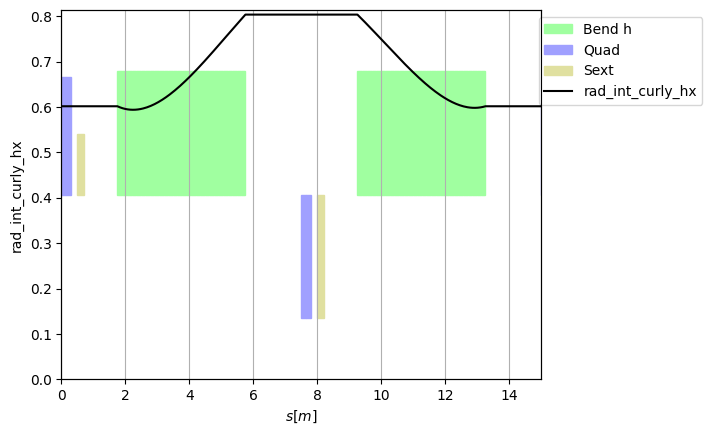

In [12]:
tw_rad.plot('rad_int_curly_hx')
plt.xlim(0, ring['l_cell'])
plt.ylim(0, None)

(0.0, 15.0)

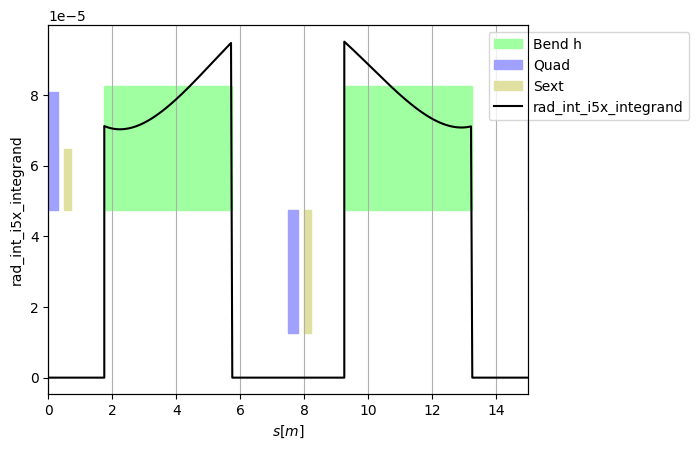

In [13]:
tw_rad.plot('rad_int_i5x_integrand')
plt.xlim(0, ring['l_cell'])

### Compare the rings

Fill the corresponding column in notebook 0. Change `lattice_file`, rerun this notebook for the other ring, and use the results and plots to answer the comparison questions.